<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/03_emendas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/03_emendas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resultado final, notebook 03: emendas parlamentares federais pagas às prefeituras do RN

**Objetivo:** medir **quanto dinheiro de emendas parlamentares federais chegou de fato a cada prefeitura do RN**, por ano
e por modalidade, e salvar em CSV para a junção do notebook 04.

**O que é uma emenda:** é a parte do orçamento da União que deputados federais e senadores escolhem para onde vai. A
emenda diz **quem decidiu** mandar o dinheiro. O **caminho** que o dinheiro faz até a prefeitura pode ser:

| Caminho | Como funciona | Está no notebook 02? |
|---|---|---|
| **Pix** (transferência especial) | O dinheiro cai direto na conta da prefeitura, sem convênio (criada pela EC 105/2019) | Não |
| **Convênio** ou contrato de repasse | O ministério assina um convênio com a prefeitura para uma obra ou compra | **Sim**: já é contado como convênio |
| **Fundo a fundo** (saúde) | Do Fundo Nacional de Saúde para o fundo municipal de saúde | Não |

**Fontes:**

| Fonte | Arquivo | O que traz |
|---|---|---|
| Portal da Transparência federal, [download de emendas](https://portaldatransparencia.gov.br/download-de-dados/emendas-parlamentares) | `dados/emendas/emendas_por_favorecido_rn.csv` | **Quanto cada favorecido recebeu**, mês a mês, de cada emenda. É a fonte principal |
| Mesmo download | `dados/emendas/emendas_por_localidade_rn.csv` | Valor empenhado e pago de cada emenda por local de aplicação (usado para a saúde) |
| Mesmo download | `dados/emendas/emendas_convenios_rn_portal.csv` | Quais emendas viraram convênio, e com qual convenente |
| Transferegov, [API das transferências especiais](https://api.transferegov.gestao.gov.br/transferenciasespeciais/) | `dados/emendas/transferegov_pix_rn.csv` | Planos de ação do Pix e as ordens bancárias pagas (usado para conferir o Pix) |

Os três primeiros arquivos são o recorte do RN do arquivo nacional `EmendasParlamentares.zip` (baixado em 12/11/2026,
dados atualizados pela CGU em 10/11/2026). O arquivo nacional tem 250 MB e não cabe no GitHub.

**O que muda em relação às bases de emendas usadas antes no projeto:**

| Problema na base anterior | Correção aqui |
|---|---|
| Filtro `contains('RN')` na localidade também pegava **PERNAMBUCO**, **GOVERNADOR VALADARES - MG** e outras | Só localidades que terminam em `- RN` e favorecidos com UF = RN |
| Convênios com mais de uma emenda tinham o **valor do convênio repetido** em cada emenda (112 casos) | O valor vem do que a prefeitura **recebeu**, por emenda, sem repetição |
| Pix pelo **valor planejado** do plano de ação, inclusive planos **impedidos** | Pix pelo valor **pago** (e conferido com as ordens bancárias do Transferegov) |
| Ano da emenda ou da publicação do convênio | **Ano em que o dinheiro foi recebido** |
| Emendas para o Governo do Estado, empresas e pessoas físicas misturadas | Só prefeituras e fundos municipais |

## 1. Bibliotecas e funções

In [4]:
import os
import re
import time
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
ANOS = [2020, 2021, 2022, 2023]
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')
pd.set_option('display.max_colwidth', 70)

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
ROXO, CINZA, CINZA_CLARO = '#7d55c7', '#a3a29b', '#d6d5d0'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    """Formata em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000 -> 'R$ 2,3 mi'."""
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, tentativas=3, **kwargs):
    """Lê do GitHub do projeto (tenta de novo se a conexão cair); se não conseguir, lê a cópia local (mesmo caminho)."""
    for _ in range(tentativas):
        try:
            return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
        except Exception as e:
            erro = e
            if '404' in str(e):
                break
            time.sleep(3)
    if os.path.exists(caminho):
        return pd.read_csv(caminho, **kwargs)
    if '404' in str(erro):
        raise FileNotFoundError(
            f'O arquivo "{caminho}" não está no GitHub do projeto. '
            f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
            'e rode a célula de novo.') from None
    raise ConnectionError(
        f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
        f'Erro original: {erro}') from None

def chave(nome):
    """Nome sem acento, pontuação e caixa: 'Olho-d'Água do Borges' -> 'OLHO DAGUA DO BORGES'."""
    texto = unicodedata.normalize('NFKD', str(nome)).encode('ascii', 'ignore').decode().upper().replace('-', ' ')
    return re.sub(r'\s+', ' ', re.sub(r'[^A-Z ]', '', texto)).strip()

def moeda(coluna):
    """'1.234,56' -> 1234.56"""
    return pd.to_numeric(coluna.astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
                         errors='coerce')

def gini(valores):
    """Índice de Gini (0 = todos recebem igual por habitante; 1 = um só recebe tudo)."""
    x = np.sort(np.asarray(valores, dtype=float))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())

def lorenz(valores):
    x = np.sort(np.asarray(valores, dtype=float))
    return np.linspace(0, 1, len(x) + 1), np.insert(np.cumsum(x), 0, 0) / x.sum()

os.makedirs('resultado_final/saida', exist_ok=True)

# Cidades em destaque, encontradas no notebook 06: recebem muito mais repasses por habitante do que as demais,
# por concentrarem parques eólicos e a produção de petróleo. Aqui servem só para marcar nos gráficos;
# a lista final sai do notebook 04, depois de juntar repasses, convênios e emendas.
CIDADES_DESTAQUE = ['Guamaré', 'São Bento do Norte', 'Pedra Grande', 'Parazinho', 'Galinhos', 'Bodó', 'Serra do Mel']

## 2. Bases de apoio: municípios, população e inflação

A população (Censo 2022) e o fator do IPCA vêm da base do notebook 01, para que os valores por habitante sejam
comparáveis aos de repasses e convênios.

In [5]:
municipios = ler_csv('dados/ibge/municipios_rn.csv')[['cod_ibge', 'municipio']]
municipios['chave'] = municipios['municipio'].map(chave)
assert municipios['chave'].is_unique and len(municipios) == 167

base01 = ler_csv('resultado_final/saida/01_base_municipios_2020_2023.csv')
rep01 = ler_csv('resultado_final/saida/01_repasses_municipios_2020_2023.csv')
conv02 = ler_csv('resultado_final/saida/02_convenios_municipios_2020_2023.csv')

ipca = ler_csv('dados/ibge/ipca_mensal.csv')
ipca_anual = ipca.assign(ano=ipca['anomes'] // 100).groupby('ano')['ipca_indice'].mean()
FATOR_IPCA = (ipca_anual[2023] / ipca_anual).rename('fator_ipca')
assert abs(FATOR_IPCA[2020] - base01.loc[base01['ano'] == 2020, 'fator_ipca'].iloc[0]) < 1e-6
ANO_MAX = int(FATOR_IPCA.index.max())

NOMES_ANTIGOS = {
    'ACU': 'ASSU',                           # Açu = Assú
    'ARES': 'AREZ',                          # Arês = Arez
    'AUGUSTO SEVERO': 'CAMPO GRANDE',        # nome antigo de Campo Grande
    'PRESIDENTE JUSCELINO': 'SERRA CAIADA',  # nome antigo de Serra Caiada
}

def para_cod_ibge(nomes):
    """Converte nomes de município (em qualquer grafia) para o código do IBGE."""
    return nomes.map(chave).replace(NOMES_ANTIGOS).map(municipios.set_index('chave')['cod_ibge'])

print(f'IPCA disponível até {ANO_MAX}: os valores de {ANO_MAX + 1} em diante ficam fora (o ano ainda não terminou).')

IPCA disponível até 2025: os valores de 2026 em diante ficam fora (o ano ainda não terminou).


## 3. Quem recebe as emendas no RN

O arquivo "por favorecido" mostra **quem recebeu o dinheiro**: prefeituras, Governo do Estado, empresas contratadas
pela União, universidades, ONGs e até pessoas físicas (bolsas, por exemplo). Para medir o que chega às prefeituras,
ficamos só com os favorecidos de natureza jurídica **Município** e **Fundo Público da Administração Direta Municipal**.

22.999 pagamentos a favorecidos do RN. de 2014 a 2026


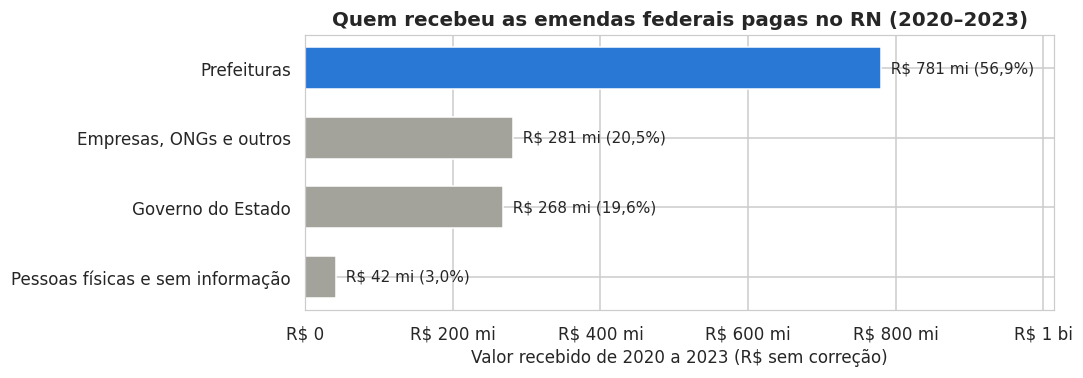

In [6]:
fav = ler_csv('dados/emendas/emendas_por_favorecido_rn.csv', dtype=str)
fav['valor'] = moeda(fav['Valor Recebido'])
fav['ano'] = fav['Ano/Mês'].str[:4].astype(int)
assert (fav['UF Favorecido'] == 'RN').all()
print(f'{len(fav):,} pagamentos a favorecidos do RN, de {fav["ano"].min()} a {fav["ano"].max()}'.replace(',', '.'))

NATUREZA_PREFEITURA = ['Município', 'Fundo Público da Administração Direta Municipal']
GRUPOS_FAVORECIDO = {
    'Município': 'Prefeituras', 'Fundo Público da Administração Direta Municipal': 'Prefeituras',
    'Órgão Público do Poder Executivo Estadual ou do Distrito Federal': 'Governo do Estado',
    'Estado ou Distrito Federal': 'Governo do Estado',
    'Fundo Público da Administração Direta Estadual ou do Distrito Federal': 'Governo do Estado',
    'Fundação Pública de Direito Público Estadual ou do Distrito Federal': 'Governo do Estado',
    'Autarquia Estadual ou do Distrito Federal': 'Governo do Estado',
    'Sem informação': 'Pessoas físicas e sem informação',
}
fav['quem'] = fav['Natureza Jurídica'].map(GRUPOS_FAVORECIDO).fillna('Empresas, ONGs e outros')

recorte = fav[fav['ano'].isin(ANOS)]
quem = recorte.groupby('quem')['valor'].sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 3.6))
cores = [AZUL if q == 'Prefeituras' else CINZA for q in quem.index]
ax.barh(quem.index, quem.values, color=cores, height=0.6)
for y, v in enumerate(quem.values):
    ax.text(v, y, f'  {reais(v)} ({virgula(v / quem.sum() * 100)}%)', va='center', fontsize=10)
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, quem.max() * 1.3)
ax.set_xlabel('Valor recebido de 2020 a 2023 (R$ sem correção)')
ax.set_title('Quem recebeu as emendas federais pagas no RN (2020–2023)')
plt.tight_layout()
plt.show()

## 4. Pagamentos às prefeituras e a modalidade de cada um

Cada pagamento é classificado em uma de três modalidades:

1. **Pix:** tipo de emenda "Transferências Especiais";
2. **Convênio:** a emenda aparece no arquivo de convênios do Portal com a **própria prefeitura** como convenente.
   Esse dinheiro **já está no notebook 02**, então não pode ser somado de novo na junção;
3. **Outras, sem convênio:** os demais pagamentos diretos à prefeitura ou ao fundo municipal (por exemplo, emendas
   de bancada e de relator transferidas fundo a fundo).

In [7]:
pref = fav[fav['Natureza Jurídica'].isin(NATUREZA_PREFEITURA)].copy()
pref['cod_ibge'] = para_cod_ibge(pref['Município Favorecido'])
assert pref['cod_ibge'].notna().all(), 'município sem código IBGE'

conv_portal = ler_csv('dados/emendas/emendas_convenios_rn_portal.csv', dtype=str)
conv_portal = conv_portal[conv_portal['Localidade do gasto'].str.endswith('- RN')
                          & conv_portal['Convenente'].str.upper().str.startswith('MUNICIPIO')]
conv_portal['cod_ibge'] = para_cod_ibge(conv_portal['Localidade do gasto'].str.replace(' - RN', '', regex=False))
pares_convenio = set(zip(conv_portal['Código da Emenda'], conv_portal['cod_ibge']))

pref['modalidade'] = np.select(
    [pref['Tipo de Emenda'].str.contains('Especiais'),
     [(e, c) in pares_convenio for e, c in zip(pref['Código da Emenda'], pref['cod_ibge'])]],
    ['Pix', 'Convênio'], default='Outras, sem convênio')
pref = pref[pref['ano'] <= ANO_MAX].copy()
pref['valor_real'] = pref['valor'] * pref['ano'].map(FATOR_IPCA)

TIPOS = {'Emenda Individual - Transferências Especiais': 'Individual (Pix)',
         'Emenda Individual - Transferências com Finalidade Definida': 'Individual (finalidade definida)',
         'Emenda de Bancada': 'Bancada', 'Emenda de Relator': 'Relator', 'Emenda de Comissão': 'Comissão'}
pref['tipo'] = pref['Tipo de Emenda'].map(TIPOS)
assert pref['tipo'].notna().all()

(pref[pref['ano'].isin(ANOS)].pivot_table(index='modalidade', columns='ano', values='valor_real', aggfunc='sum')
 .div(1e6).assign(**{'Total 2020–2023': lambda d: d.sum(axis=1)}).round(1))

ano,2020,2021,2022,2023,Total 2020–2023
modalidade,,,,,
Convênio,180.5,74.9,149.7,115.9,521.0
"Outras, sem convênio",5.2,5.5,10.6,22.5,43.7
Pix,22.1,43.9,26.0,187.5,279.5


### 4.1 Conferência do Pix com o Transferegov

O Transferegov registra cada ordem bancária das transferências especiais. Se a classificação estiver certa, o Pix
recebido pelas prefeituras no Portal deve bater com as ordens bancárias pagas a prefeituras no Transferegov.

A API pode ser consultada de novo com `BAIXAR_TRANSFEREGOV = True` (leva uns 2 minutos); o padrão é ler a cópia
salva em `dados/emendas/transferegov_pix_rn.csv`.

In [8]:
BAIXAR_TRANSFEREGOV = False

def baixar_transferegov():
    """Planos de ação do RN -> empenhos -> documentos hábeis -> ordens bancárias, pela API pública (PostgREST)."""
    import requests
    api = 'https://api.transferegov.gestao.gov.br/transferenciasespeciais/'
    def pegar(tabela, filtro=None, campo=None, ids=None):
        linhas, grupos = [], [None] if ids is None else [ids[i:i + 150] for i in range(0, len(ids), 150)]
        for grupo in grupos:
            inicio = 0
            while True:
                params = dict(filtro or {}, limit=1000, offset=inicio)
                if grupo is not None:
                    params[campo] = 'in.(' + ','.join(map(str, grupo)) + ')'
                parte = requests.get(api + tabela, params=params, timeout=120).json()
                linhas += parte
                if len(parte) < 1000:
                    break
                inicio += 1000
        return pd.DataFrame(linhas)
    planos = pegar('plano_acao_especial', {'uf_beneficiario_plano_acao': 'eq.RN'})
    empenhos = pegar('empenho_especial', campo='id_plano_acao', ids=sorted(planos['id_plano_acao']))
    docs = pegar('documento_habil_especial', campo='id_empenho', ids=sorted(empenhos['id_empenho']))
    ordens = pegar('ordem_pagamento_ordem_bancaria_especial', campo='id_dh', ids=sorted(docs['id_dh']))
    pagos = (ordens[ordens['data_emissao_ob'].notna()][['id_dh', 'data_emissao_ob']]
             .merge(docs[['id_dh', 'valor_dh', 'id_empenho']], on='id_dh')
             .merge(empenhos[['id_empenho', 'id_plano_acao']], on='id_empenho'))
    pagos['ano_pagamento'] = pagos['data_emissao_ob'].str[:4].astype(int)
    por_plano = (pagos.pivot_table(index='id_plano_acao', columns='ano_pagamento', values='valor_dh', aggfunc='sum')
                 .add_prefix('pago_').reset_index())
    return planos.merge(por_plano, on='id_plano_acao', how='left')

pix_tg = baixar_transferegov() if BAIXAR_TRANSFEREGOV else ler_csv('dados/emendas/transferegov_pix_rn.csv')
pix_tg_pref = pix_tg[pix_tg['nome_beneficiario_plano_acao'].str.upper().str.startswith('MUNICIPIO')]

conferencia = pd.DataFrame({
    'Portal: Pix recebido pelas prefeituras': pref[pref['modalidade'] == 'Pix'].groupby('ano')['valor'].sum(),
    'Transferegov: ordens bancárias pagas': pd.Series({a: pix_tg_pref.get(f'pago_{a}', pd.Series(dtype=float)).sum()
                                                       for a in range(2020, ANO_MAX + 1)}),
}).loc[2020:ANO_MAX].div(1e6)
conferencia.loc['Total 2020–2023'] = conferencia.loc[2020:2023].sum()
conferencia['Diferença (%)'] = (conferencia.iloc[:, 0] / conferencia.iloc[:, 1] - 1) * 100
conferencia.loc[[2020, 2021, 2022, 2023, 'Total 2020–2023']].round(1)

,Portal: Pix recebido pelas prefeituras,Transferegov: ordens bancárias pagas,Diferença (%)
2020,17.8,17.8,0.0
2021,38.4,39.1,-1.7
2022,24.9,25.6,-3.0
2023,187.5,176.6,6.1
Total 2020–2023,268.6,259.2,3.6


**Leitura:** as duas fontes contam o mesmo Pix: no total de 2020 a 2023 a diferença é de poucos por cento. As
diferenças de um ano para outro vêm da data: o Transferegov usa a data da ordem bancária e o Portal, o mês em que o
crédito foi registrado, então pagamentos de fim de dezembro podem cair em anos diferentes. (Em 2024 e 2025, fora do
recorte, o Portal fica cerca de 12% acima do Transferegov.)

Outra lição dessa conferência: o **valor planejado** do Pix (o que a base anterior usava) é bem diferente do pago,
porque planos impedidos não são pagos e muitos planos de um ano são pagos no ano seguinte.

In [9]:
planejado = (pix_tg_pref.assign(valor=pix_tg_pref['valor_custeio_plano_acao'] + pix_tg_pref['valor_investimento_plano_acao'])
             .groupby('ano_plano_acao')['valor'].sum().loc[2020:2023] / 1e6)
pd.DataFrame({'Planejado (ano do plano)': planejado,
              'Pago (ano do pagamento)': conferencia.iloc[:, 1].loc[2020:2023]}).round(1)

,Planejado (ano do plano),Pago (ano do pagamento)
2020,17.8,17.8
2021,40.5,39.1
2022,58.7,25.6
2023,151.9,176.6


## 5. Visão geral

### 5.1 Por ano e modalidade

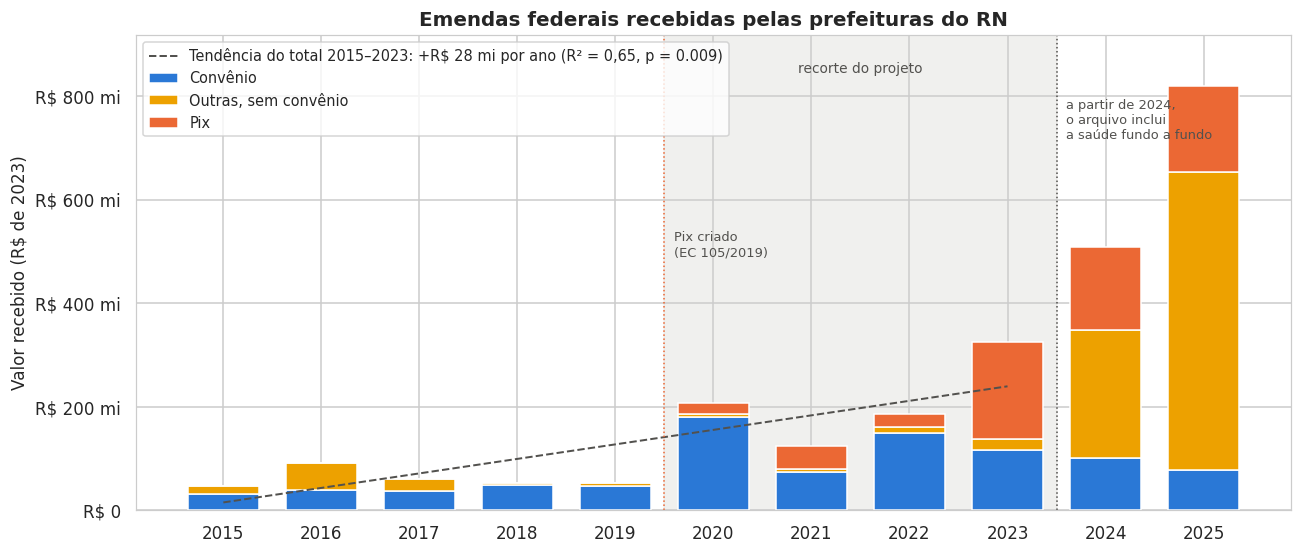

Participação do Pix no total recebido: 2020: 10,6% | 2021: 35,3% | 2022: 14,0% | 2023: 57,5% | 2024: 31,7% | 2025: 20,4%


modalidade,Convênio,"Outras, sem convênio",Pix,Total
ano,,,,
2018,49.8,2.3,0.0,52.1
2019,46.9,5.4,0.0,52.3
2020,180.5,5.2,22.1,207.8
2021,74.9,5.5,43.9,124.3
2022,149.7,10.6,26.0,186.2
2023,115.9,22.5,187.5,325.9
2024,101.8,245.5,161.4,508.7
2025,77.4,574.8,167.3,819.5


In [10]:
por_ano = pref.pivot_table(index='ano', columns='modalidade', values='valor_real', aggfunc='sum').fillna(0)
por_ano = por_ano.reindex(range(2015, ANO_MAX + 1), fill_value=0)
ORDEM_MOD = [('Convênio', AZUL), ('Outras, sem convênio', AMARELO), ('Pix', LARANJA)]

fig, ax = plt.subplots(figsize=(12, 5.2))
fundo = np.zeros(len(por_ano))
for mod, cor in ORDEM_MOD:
    ax.bar(por_ano.index, por_ano[mod], bottom=fundo, color=cor, label=mod, width=0.72, edgecolor='white', linewidth=1)
    fundo += por_ano[mod].values
anos_x = por_ano.loc[:2023].index.values
inclinacao, intercepto, r, p, _ = stats.linregress(anos_x, fundo[:len(anos_x)])
ax.plot(anos_x, intercepto + inclinacao * anos_x, color=TEXTO_2, linestyle='--', linewidth=1.3,
        label=f'Tendência do total 2015–2023: +{reais(inclinacao)} por ano (R² = {virgula(r ** 2, 2)}, p = {p:.3f})')
ax.axvline(2023.5, color=TEXTO_2, linestyle=':', linewidth=1)
ax.text(2023.6, fundo.max() * 0.97, 'a partir de 2024,\no arquivo inclui\na saúde fundo a fundo', fontsize=8.5,
        color=TEXTO_2, va='top')
ax.axvspan(2019.5, 2023.5, color=CINZA_CLARO, alpha=0.35, zorder=0)
ax.text(2021.5, fundo.max() * 1.03, 'recorte do projeto', ha='center', fontsize=9, color=TEXTO_2)
ax.axvline(2019.5, color=LARANJA, linestyle=':', linewidth=1)
ax.text(2019.6, fundo.max() * 0.6, 'Pix criado\n(EC 105/2019)', fontsize=8.5, color=TEXTO_2)
ax.yaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xticks(por_ano.index)
ax.set_ylim(0, fundo.max() * 1.12)
ax.set_ylabel('Valor recebido (R$ de 2023)')
ax.set_title('Emendas federais recebidas pelas prefeituras do RN')
ax.legend(loc='upper left', fontsize=9.5)
plt.tight_layout()
plt.show()

participacao_pix = (por_ano['Pix'] / por_ano.sum(axis=1) * 100).loc[2020:]
print('Participação do Pix no total recebido:', ' | '.join(f'{a}: {virgula(v)}%' for a, v in participacao_pix.items()))
por_ano.loc[2018:].div(1e6).assign(Total=lambda d: d.sum(axis=1)).round(1)

### 5.2 Por tipo de emenda

- **Individual:** cada deputado e senador tem uma cota igual, de execução obrigatória.
- **Bancada:** decidida em conjunto pelos parlamentares do estado.
- **Relator:** a chamada "RP9", distribuída pelo relator do orçamento sem identificar o parlamentar que pediu. O STF
  declarou essa modalidade inconstitucional em dezembro de 2022; o que aparece depois disso são pagamentos de restos.

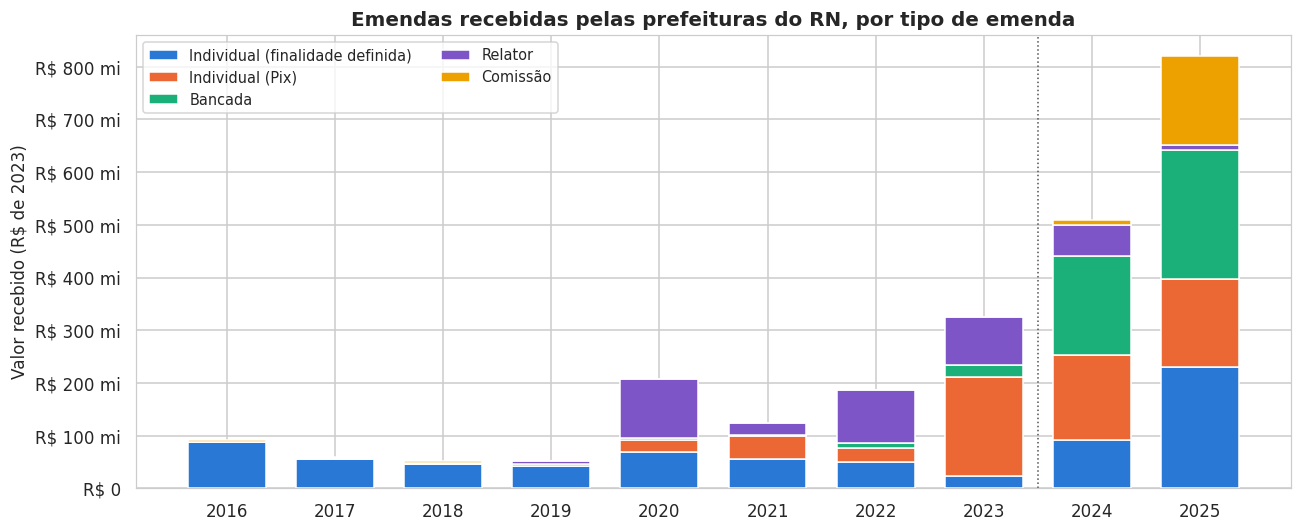

,Valor 2020–2023 (R$ mi de 2023),% do total
tipo,,
Relator,327.4,38.8
Individual (Pix),279.5,33.1
Individual (finalidade definida),199.4,23.6
Bancada,37.5,4.4
Comissão,0.5,0.1


In [11]:
por_tipo = pref.pivot_table(index='ano', columns='tipo', values='valor_real', aggfunc='sum').fillna(0).loc[2016:ANO_MAX]
ORDEM_TIPO = [('Individual (finalidade definida)', AZUL), ('Individual (Pix)', LARANJA), ('Bancada', VERDE),
              ('Relator', ROXO), ('Comissão', AMARELO)]
fig, ax = plt.subplots(figsize=(12, 5))
fundo = np.zeros(len(por_tipo))
for tipo, cor in ORDEM_TIPO:
    if tipo in por_tipo:
        ax.bar(por_tipo.index, por_tipo[tipo], bottom=fundo, color=cor, label=tipo, width=0.72, edgecolor='white', linewidth=1)
        fundo += por_tipo[tipo].values
ax.yaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xticks(por_tipo.index)
ax.axvline(2023.5, color=TEXTO_2, linestyle=':', linewidth=1)
ax.set_ylabel('Valor recebido (R$ de 2023)')
ax.set_title('Emendas recebidas pelas prefeituras do RN, por tipo de emenda')
ax.legend(loc='upper left', fontsize=9.5, ncol=2)
plt.tight_layout()
plt.show()

(pref[pref['ano'].isin(ANOS)].groupby('tipo')['valor_real'].sum()
 .pipe(lambda s: pd.DataFrame({'Valor 2020–2023 (R$ mi de 2023)': s / 1e6, '% do total': s / s.sum() * 100}))
 .sort_values('% do total', ascending=False).round(1))

### 5.3 E a saúde fundo a fundo?

Uma parte grande das emendas vai da União para os **fundos municipais de saúde** (por exemplo, "incremento temporário
ao custeio da atenção primária"). Esse dinheiro **não aparece no arquivo por favorecido**, e no arquivo por localidade
fica registrado como **"MÚLTIPLO"** ou como o estado inteiro, sem dizer qual município recebeu.

Por isso ele não entra na conta por município deste notebook. Abaixo está o tamanho do que fica de fora, para não
esquecer na hora das conclusões.

In [12]:
loc = ler_csv('dados/emendas/emendas_por_localidade_rn.csv', dtype=str)
for col in ['Valor Pago', 'Valor Restos A Pagar Pagos']:
    loc[col] = moeda(loc[col])
loc['ano'] = loc['Ano da Emenda'].astype(int)
loc['pago'] = loc['Valor Pago'] + loc['Valor Restos A Pagar Pagos']
loc['nivel'] = np.where(loc['Localidade de aplicação do recurso'].str.endswith('- RN'), 'Um município',
                        'Vários municípios ou o estado inteiro')
saude_ff = loc[loc['Nome Ação'].str.startswith('INCREMENTO TEMPORARIO') & loc['ano'].isin(ANOS)]
tabela_saude = saude_ff.pivot_table(index='ano', columns='nivel', values='pago', aggfunc='sum').fillna(0) / 1e6
tabela_saude['Total'] = tabela_saude.sum(axis=1)
recebido_pref = pref[pref['ano'].isin(ANOS)].groupby('ano')['valor'].sum() / 1e6
tabela_saude['Comparação: tudo o que as prefeituras receberam no arquivo por favorecido'] = recebido_pref
print('Emendas de "incremento temporário" da saúde no RN, por ano da emenda (R$ mi, sem correção):')
tabela_saude.round(1)

Emendas de "incremento temporário" da saúde no RN, por ano da emenda (R$ mi, sem correção):


nivel,Um município,Vários municípios ou o estado inteiro,Total,Comparação: tudo o que as prefeituras receberam no arquivo por favorecido
ano,,,,
2020,0.2,90.4,90.7,167.8
2021,0.5,137.5,137.9,108.8
2022,17.0,157.8,174.8,178.1
2023,15.2,304.2,319.3,325.9


**Leitura:** de 2020 a 2023, a saúde fundo a fundo soma algo da mesma ordem de tudo o que as prefeituras receberam
pelas outras modalidades, e quase nada dela tem município identificado. Então o total de emendas por município deste
notebook é um **piso**: o valor real recebido é maior, principalmente nos municípios que receberam incremento de saúde.

**A partir de 2024 isso muda:** depois das decisões do STF sobre transparência das emendas, os fundos municipais de
saúde passam a aparecer como favorecidos no arquivo. Por isso a modalidade "Outras, sem convênio" salta em 2024 e
2025 nos gráficos da seção 5. É uma mudança no **registro**, e não só no volume de dinheiro: comparar 2024–2025 com os
anos anteriores exige esse cuidado.

In [13]:
(fav[fav['Natureza Jurídica'].isin(NATUREZA_PREFEITURA)].pivot_table(index='ano', columns='Natureza Jurídica',
                                                                    values='valor', aggfunc='sum')
 .loc[2019:ANO_MAX].div(1e6).round(1)
 .rename(columns={'Fundo Público da Administração Direta Municipal': 'Fundos municipais (R$ mi)',
                  'Município': 'Prefeitura (R$ mi)'}))

Natureza Jurídica,Fundos municipais (R$ mi),Prefeitura (R$ mi)
ano,,
2019,2.4,38.6
2020,1.2,166.6
2021,2.2,106.6
2022,7.6,170.4
2023,13.9,311.9
2024,255.2,275.7
2025,629.2,269.0


A fonte para completar a saúde de 2020 a 2023 por município é o Fundo Nacional de Saúde (consulta de repasses fundo a
fundo por emenda), que fica como próximo passo.

## 6. Por município (2020–2023)

In [14]:
recorte_pref = pref[pref['ano'].isin(ANOS)]
mun = (recorte_pref.pivot_table(index='cod_ibge', columns='modalidade', values='valor_real', aggfunc='sum')
       .rename(columns={'Pix': 'pix_valor', 'Convênio': 'convenio_valor', 'Outras, sem convênio': 'outras_valor'}))
mun = (municipios[['cod_ibge', 'municipio']].merge(rep01[['cod_ibge', 'mesorregiao', 'populacao', 'porte',
                                                            'pib_per_capita', 'pct_baixa_renda', 'rep_total_pc_ano']],
                                                     on='cod_ibge')
       .merge(mun.reset_index(), on='cod_ibge', how='left').fillna({'pix_valor': 0, 'convenio_valor': 0, 'outras_valor': 0}))
mun['n_emendas'] = mun['cod_ibge'].map(recorte_pref.groupby('cod_ibge')['Código da Emenda'].nunique()).fillna(0).astype(int)
mun['total_valor'] = mun[['pix_valor', 'convenio_valor', 'outras_valor']].sum(axis=1)
mun['sem_convenio_valor'] = mun['pix_valor'] + mun['outras_valor']
for col in ['pix_valor', 'convenio_valor', 'outras_valor', 'total_valor', 'sem_convenio_valor']:
    mun[col.replace('_valor', '_pc_ano')] = mun[col] / mun['populacao'] / len(ANOS)
mun['posicao_emendas'] = mun['total_pc_ano'].rank(ascending=False, method='min').astype(int)
assert len(mun) == 167 and abs(mun['total_valor'].sum() - recorte_pref['valor_real'].sum()) < 1

mediana = mun['total_pc_ano'].median()
print(f'Municípios que receberam alguma emenda em 2020–2023: {(mun["total_valor"] > 0).sum()} de 167')
print(f'Mediana: R$ {virgula(mediana, 0)} por habitante por ano | média: R$ {virgula(mun["total_pc_ano"].mean(), 0)}')
mun.sort_values('total_pc_ano', ascending=False)[['municipio', 'populacao', 'n_emendas', 'pix_pc_ano', 'convenio_pc_ano',
                                                  'outras_pc_ano', 'total_pc_ano']].head(10)

Municípios que receberam alguma emenda em 2020–2023: 167 de 167
Mediana: R$ 98 por habitante por ano | média: R$ 123


,municipio,populacao,n_emendas,pix_pc_ano,convenio_pc_ano,outras_pc_ano,total_pc_ano
116,Riacho da Cruz,2701,16,427.1,275.9,35.0,738.0
83,Messias Targino,4274,10,204.4,261.0,63.9,529.3
165,Viçosa,1822,11,205.5,314.1,0.0,519.6
103,Pedra Grande,3618,8,304.4,139.7,21.9,466.1
0,Acari,10597,17,334.2,127.1,0.0,461.3
157,Timbaúba dos Batistas,2348,11,320.0,76.8,0.0,396.9
53,Itajá,7292,16,205.1,161.5,11.6,378.2
70,Lagoa de Velhos,2567,15,210.0,152.9,6.9,369.9
95,Parazinho,4801,10,107.3,216.7,0.0,324.0
45,Galinhos,2104,7,149.7,118.9,0.0,268.6


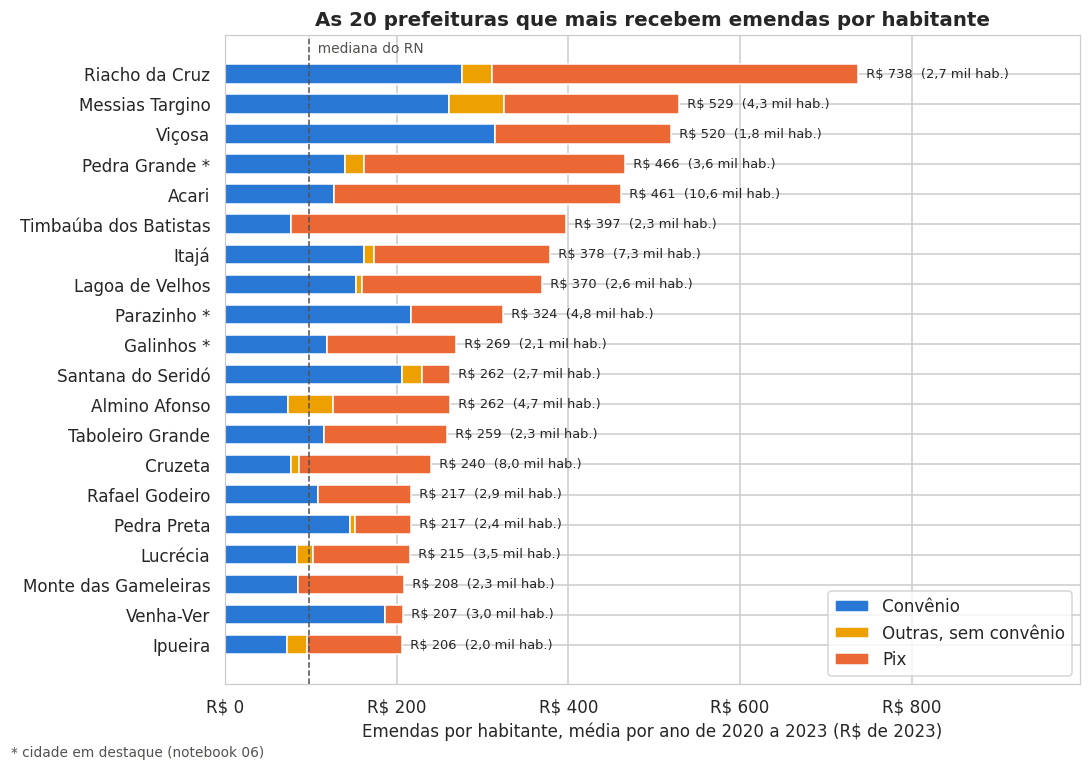

In [15]:
top = mun.sort_values('total_pc_ano', ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(top))
esquerda = np.zeros(len(top))
for mod, cor in ORDEM_MOD:
    col = {'Pix': 'pix_pc_ano', 'Convênio': 'convenio_pc_ano', 'Outras, sem convênio': 'outras_pc_ano'}[mod]
    ax.barh(y, top[col], left=esquerda, color=cor, height=0.65, label=mod, edgecolor='white', linewidth=1)
    esquerda += top[col].values
for yi, (total, pop) in zip(y, zip(top['total_pc_ano'], top['populacao'])):
    ax.text(total, yi, f'  R$ {virgula(total, 0)}  ({virgula(pop / 1000)} mil hab.)', va='center', fontsize=8.5)
ax.axvline(mediana, color=TEXTO_2, linestyle='--', linewidth=1)
ax.text(mediana, len(top) - 0.3, '  mediana do RN', fontsize=9, color=TEXTO_2)
ax.set_yticks(y)
ax.set_yticklabels([f'{m} *' if m in CIDADES_DESTAQUE else m for m in top['municipio']])
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, top['total_pc_ano'].max() * 1.35)
ax.set_xlabel('Emendas por habitante, média por ano de 2020 a 2023 (R$ de 2023)')
ax.set_title('As 20 prefeituras que mais recebem emendas por habitante')
ax.legend(loc='lower right')
fig.text(0.01, 0.005, '* cidade em destaque (notebook 06)', fontsize=9, color=TEXTO_2)
plt.tight_layout()
plt.show()

### 6.1 O tamanho do município explica boa parte

Uma emenda costuma ter valor redondo (RS 250 mil, RS 500 mil...), seja qual for o tamanho da cidade. O mesmo valor
rende muito mais por habitante numa cidade de 3 mil pessoas do que numa de 300 mil. O gráfico abaixo testa isso, em
escala logarítmica nos dois eixos (cada marca vale 10 vezes a anterior).

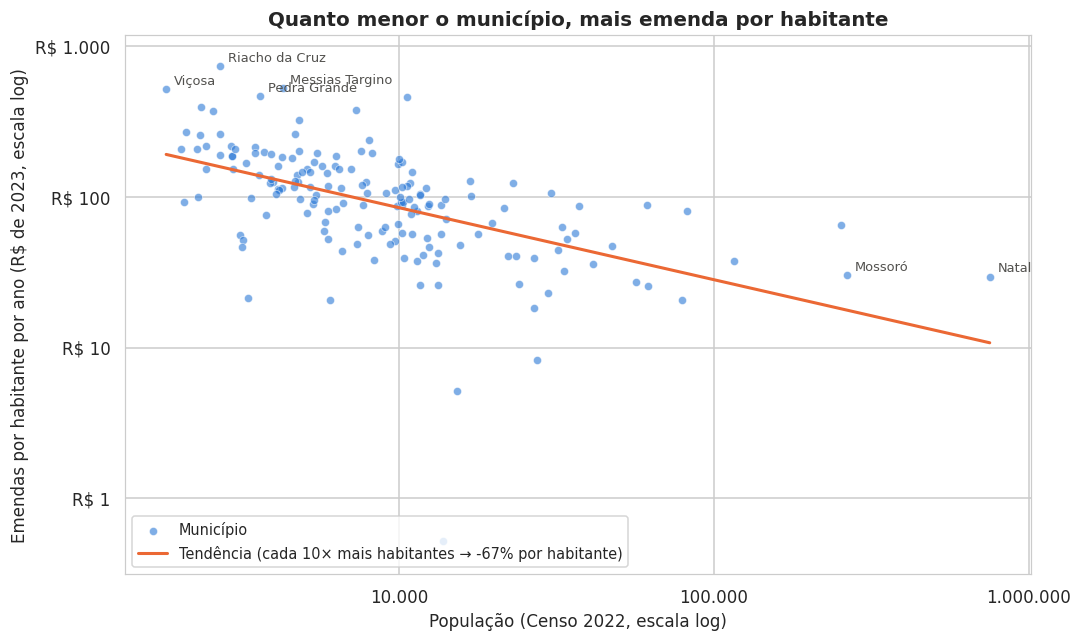

Correlação de Spearman entre população e emendas por habitante: -0,65 (p = 9.2e-22) | R² da reta em log: 0,29


In [16]:
com_emenda = mun[mun['total_valor'] > 0]
x_log, y_log = np.log10(com_emenda['populacao']), np.log10(com_emenda['total_pc_ano'])
ajuste = stats.linregress(x_log, y_log)
rho, p_rho = stats.spearmanr(com_emenda['populacao'], com_emenda['total_pc_ano'])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(com_emenda['populacao'], com_emenda['total_pc_ano'], s=28, color=AZUL, alpha=0.6, edgecolor='white',
           linewidth=0.5, label='Município')
xs = np.linspace(x_log.min(), x_log.max(), 50)
ax.plot(10 ** xs, 10 ** (ajuste.intercept + ajuste.slope * xs), color=LARANJA, linewidth=2,
        label=f'Tendência (cada 10× mais habitantes → {virgula(10 ** ajuste.slope * 100 - 100, 0)}% por habitante)')
for _, linha in com_emenda.nlargest(4, 'total_pc_ano').iterrows():
    ax.annotate(linha['municipio'], (linha['populacao'], linha['total_pc_ano']), xytext=(5, 3),
                textcoords='offset points', fontsize=8.5, color=TEXTO_2)
for nome in ['Natal', 'Mossoró']:
    linha = com_emenda[com_emenda['municipio'] == nome].iloc[0]
    ax.annotate(nome, (linha['populacao'], linha['total_pc_ano']), xytext=(5, 3), textcoords='offset points',
                fontsize=8.5, color=TEXTO_2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'R$ {v:,.0f}'.replace(',', '.')))
ax.set_ylim(com_emenda['total_pc_ano'].min() * 0.6, com_emenda['total_pc_ano'].max() * 1.6)
ax.set_xlabel('População (Censo 2022, escala log)')
ax.set_ylabel('Emendas por habitante por ano (R$ de 2023, escala log)')
ax.set_title('Quanto menor o município, mais emenda por habitante')
ax.legend(loc='lower left', fontsize=9.5)
plt.tight_layout()
plt.show()
print(f'Correlação de Spearman entre população e emendas por habitante: {virgula(rho, 2)} (p = {p_rho:.1e}) | '
      f'R² da reta em log: {virgula(ajuste.rvalue ** 2, 2)}')

### 6.2 As emendas vão para os municípios mais pobres?

Comparamos as emendas por habitante com duas medidas de pobreza: o **PIB por habitante** e a **% da população de baixa
renda no CadÚnico** (médias de 2020 a 2023, do notebook 01). Usamos a **correlação de Spearman**, que compara as
posições (rankings) e não é distorcida por poucos valores muito altos.

Como o tamanho do município pesa muito (seção 6.1), também calculamos a **correlação parcial**: a relação que sobra
depois de descontar o efeito da população.

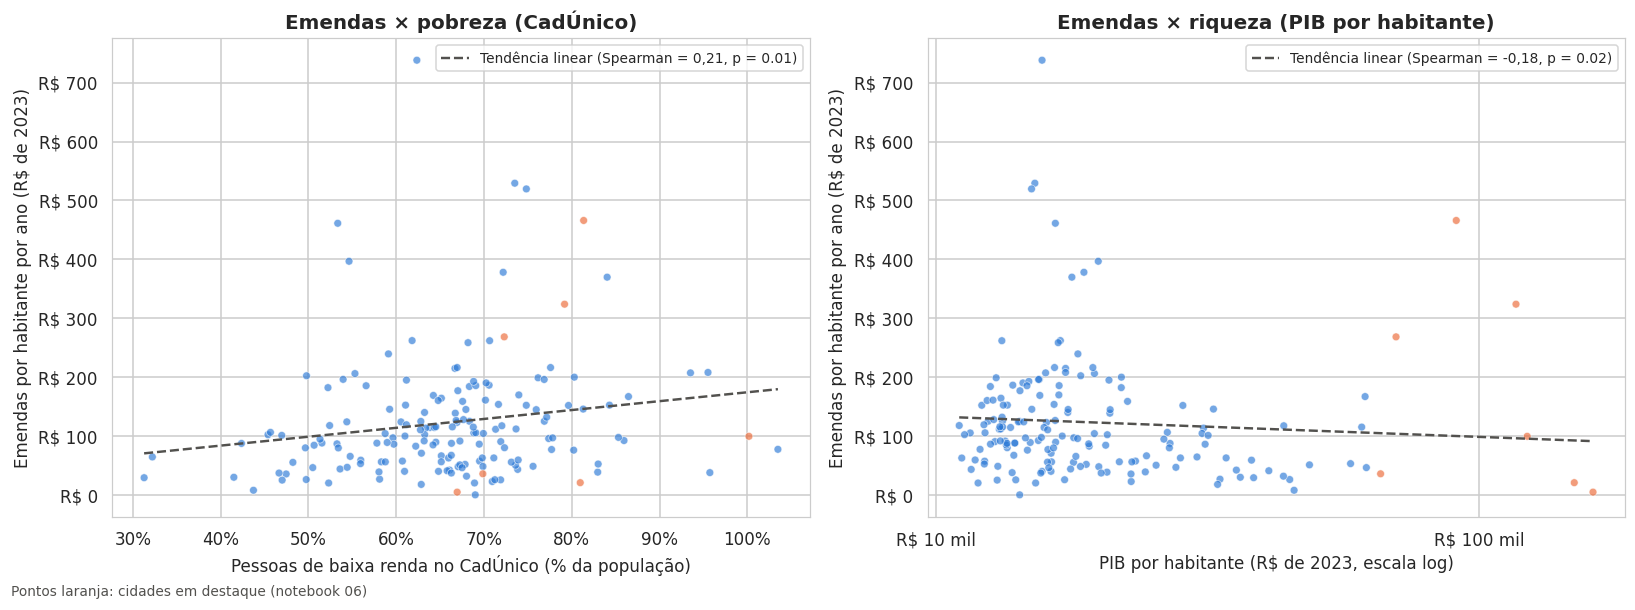

,Spearman,p-valor,Parcial (sem efeito da população),p-valor parcial
Medida,,,,
Pessoas de baixa renda no CadÚnico,"0,213","0,006","-0,202","0,009"
PIB por habitante,"-0,180","0,020","-0,065","0,402"


In [17]:
def correlacao_parcial(dados, x, y, controle):
    """Spearman entre x e y, descontando o efeito de 'controle' (resíduos dos rankings)."""
    r = dados[[x, y, controle]].rank()
    res_x = r[x] - np.poly1d(np.polyfit(r[controle], r[x], 1))(r[controle])
    res_y = r[y] - np.poly1d(np.polyfit(r[controle], r[y], 1))(r[controle])
    return stats.pearsonr(res_x, res_y)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
linhas_tabela = []
for ax, (col, rotulo, fmt) in zip(axes, [
        ('pct_baixa_renda', 'Pessoas de baixa renda no CadÚnico (% da população)', lambda v, _: f'{v:.0f}%'),
        ('pib_per_capita', 'PIB por habitante (R$ de 2023, escala log)', lambda v, _: reais(v))]):
    eixo_x = np.log10(mun[col]) if col == 'pib_per_capita' else mun[col]
    reta = stats.linregress(eixo_x, mun['total_pc_ano'])
    rho, p = stats.spearmanr(mun[col], mun['total_pc_ano'])
    r_parcial, p_parcial = correlacao_parcial(mun, col, 'total_pc_ano', 'populacao')
    linhas_tabela.append({'Medida': rotulo.split(' (')[0], 'Spearman': rho, 'p-valor': p,
                          'Parcial (sem efeito da população)': r_parcial, 'p-valor parcial': p_parcial})
    cores_pontos = [LARANJA if m in CIDADES_DESTAQUE else AZUL for m in mun['municipio']]
    ax.scatter(mun[col], mun['total_pc_ano'], s=26, c=cores_pontos, alpha=0.65, edgecolor='white', linewidth=0.5)
    xs = np.linspace(eixo_x.min(), eixo_x.max(), 50)
    ax.plot(10 ** xs if col == 'pib_per_capita' else xs, reta.intercept + reta.slope * xs, color=TEXTO_2,
            linestyle='--', linewidth=1.6, label=f'Tendência linear (Spearman = {virgula(rho, 2)}, p = {p:.2f})')
    if col == 'pib_per_capita':
        ax.set_xscale('log')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
    ax.yaxis.set_major_formatter(FORMATO_REAIS)
    ax.set_xlabel(rotulo)
    ax.set_ylabel('Emendas por habitante por ano (R$ de 2023)')
    ax.legend(loc='upper right', fontsize=9)
axes[0].set_title('Emendas × pobreza (CadÚnico)')
axes[1].set_title('Emendas × riqueza (PIB por habitante)')
fig.text(0.01, 0.0, 'Pontos laranja: cidades em destaque (notebook 06)', fontsize=9, color=TEXTO_2)
plt.tight_layout()
plt.show()
(pd.DataFrame(linhas_tabela).set_index('Medida')
 .apply(lambda col: col.map(lambda v: f'{v:.3f}'.replace('.', ','))))

### 6.3 Desigualdade: emendas × repasses × convênios

O **índice de Gini** resume quão concentrado está o dinheiro por habitante: 0 seria todos os municípios recebendo o
mesmo valor por habitante; quanto mais perto de 1, mais concentrado. A **curva de Lorenz** mostra a mesma ideia:
quanto mais longe da diagonal, mais desigual.

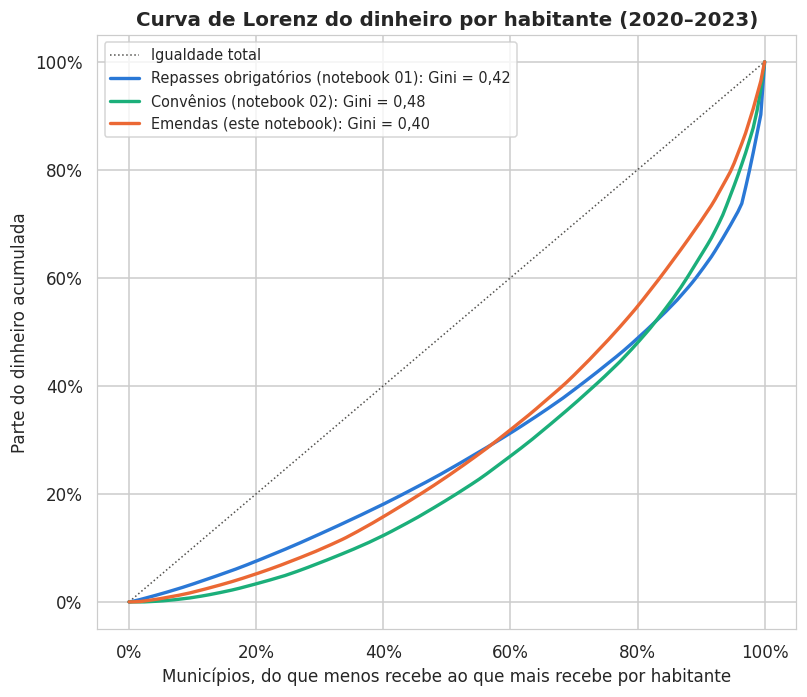

Gini das emendas por habitante, ano a ano: 2020: 0,50 | 2021: 0,55 | 2022: 0,52 | 2023: 0,49


In [18]:
comparacao = mun[['cod_ibge', 'total_pc_ano', 'rep_total_pc_ano']].merge(conv02[['cod_ibge', 'total_pc_ano']]
                                                                         .rename(columns={'total_pc_ano': 'conv_pc_ano'}),
                                                                         on='cod_ibge')
FLUXOS = [('rep_total_pc_ano', 'Repasses obrigatórios (notebook 01)', AZUL),
          ('conv_pc_ano', 'Convênios (notebook 02)', VERDE),
          ('total_pc_ano', 'Emendas (este notebook)', LARANJA)]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], color=TEXTO_2, linestyle=':', linewidth=1, label='Igualdade total')
for col, nome, cor in FLUXOS:
    xs, ys = lorenz(comparacao[col])
    ax.plot(xs, ys, color=cor, linewidth=2.2, label=f'{nome}: Gini = {virgula(gini(comparacao[col]), 2)}')
ax.set_xlabel('Municípios, do que menos recebe ao que mais recebe por habitante')
ax.set_ylabel('Parte do dinheiro acumulada')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_title('Curva de Lorenz do dinheiro por habitante (2020–2023)')
ax.legend(loc='upper left', fontsize=9.5)
plt.tight_layout()
plt.show()

# Gini ano a ano das emendas
pop = mun.set_index('cod_ibge')['populacao']
gini_ano = {}
for ano in ANOS:
    valor = recorte_pref[recorte_pref['ano'] == ano].groupby('cod_ibge')['valor_real'].sum().reindex(pop.index, fill_value=0)
    gini_ano[ano] = gini(valor / pop)
print('Gini das emendas por habitante, ano a ano:', ' | '.join(f'{a}: {virgula(g, 2)}' for a, g in gini_ano.items()))

### 6.4 Quem mais mandou emendas às prefeituras do RN

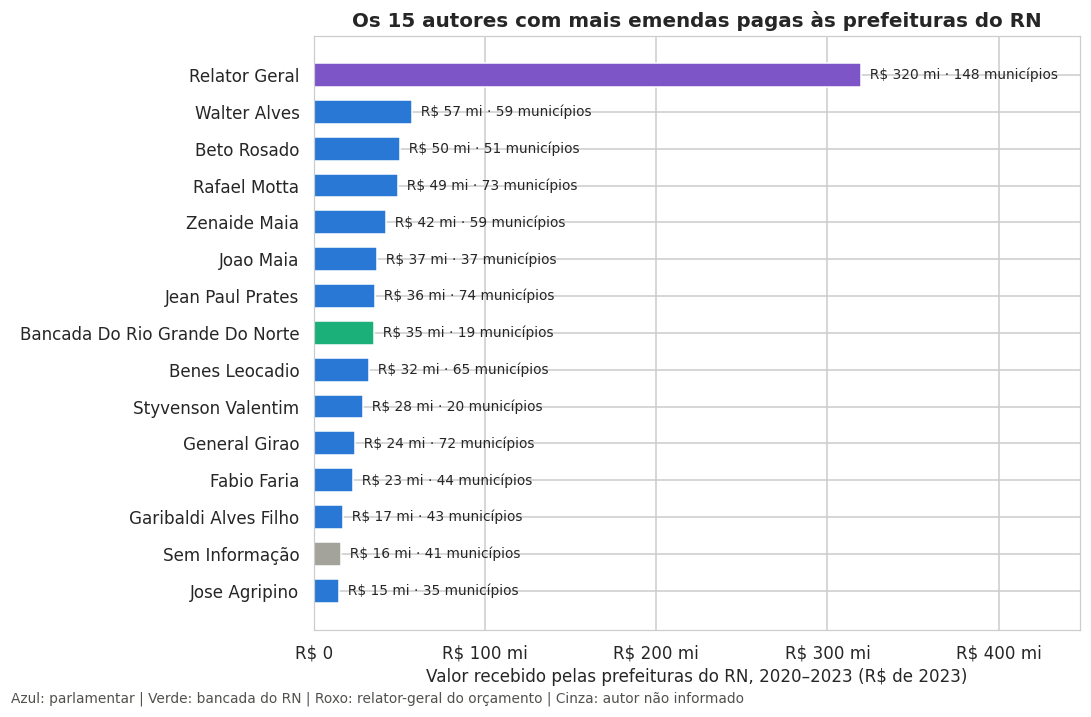

In [19]:
autores = (recorte_pref.groupby(['Nome do Autor da Emenda', 'tipo'])['valor_real'].sum().reset_index()
           .groupby('Nome do Autor da Emenda').agg(valor=('valor_real', 'sum'),
                                                   tipo=('tipo', lambda s: ' + '.join(sorted(set(s))))))
autores['municipios'] = recorte_pref.groupby('Nome do Autor da Emenda')['cod_ibge'].nunique()
autores = autores.sort_values('valor', ascending=False)
top_aut = autores.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
cores_aut = [ROXO if 'RELATOR' in n.upper() else VERDE if 'BANCADA' in n.upper() else CINZA if 'SEM INFORMA' in n.upper()
             else AZUL for n in top_aut.index]
ax.barh(top_aut.index.str.title(), top_aut['valor'], color=cores_aut, height=0.65)
for y, (v, n) in enumerate(zip(top_aut['valor'], top_aut['municipios'])):
    ax.text(v, y, f'  {reais(v)} · {n} municípios', va='center', fontsize=9)
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, top_aut['valor'].max() * 1.4)
ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
ax.set_xlabel('Valor recebido pelas prefeituras do RN, 2020–2023 (R$ de 2023)')
ax.set_title('Os 15 autores com mais emendas pagas às prefeituras do RN')
fig.text(0.01, 0.005, 'Azul: parlamentar | Verde: bancada do RN | Roxo: relator-geral do orçamento | Cinza: autor não informado', fontsize=9,
         color=TEXTO_2)
plt.tight_layout()
plt.show()

### 6.5 E as cidades em destaque?

In [20]:
(mun.loc[mun['municipio'].isin(CIDADES_DESTAQUE)].set_index('municipio')
 [['populacao', 'n_emendas', 'pix_pc_ano', 'convenio_pc_ano', 'outras_pc_ano', 'total_pc_ano', 'posicao_emendas']]
 .sort_values('posicao_emendas')
 .assign(**{'Emendas ÷ repasses': lambda d: d['total_pc_ano'] / mun.set_index('municipio').loc[d.index, 'rep_total_pc_ano']})
 .rename(columns={'populacao': 'População', 'n_emendas': 'Emendas', 'pix_pc_ano': 'Pix (R$/hab/ano)',
                  'convenio_pc_ano': 'Convênio (R$/hab/ano)', 'outras_pc_ano': 'Outras (R$/hab/ano)',
                  'total_pc_ano': 'Total (R$/hab/ano)', 'posicao_emendas': 'Posição no RN (de 167)'}))

,População,Emendas,Pix (R$/hab/ano),Convênio (R$/hab/ano),Outras (R$/hab/ano),Total (R$/hab/ano),Posição no RN (de 167),Emendas ÷ repasses
municipio,,,,,,,,
Pedra Grande,3618,8,304.4,139.7,21.9,466.1,4,0.1
Parazinho,4801,10,107.3,216.7,0.0,324.0,9,0.1
Galinhos,2104,7,149.7,118.9,0.0,268.6,10,0.1
Bodó,2306,4,0.0,78.2,21.7,99.8,83,0.0
Serra do Mel,13091,2,12.4,23.8,0.0,36.2,150,0.0
São Bento do Norte,3304,2,21.2,0.0,0.0,21.2,161,0.0
Guamaré,15295,2,1.7,0.0,3.4,5.1,166,0.0


## 7. Arquivos finais

| Arquivo | Conteúdo |
|---|---|
| `resultado_final/saida/03_emendas_municipio_ano.csv` | Uma linha por **município, ano, modalidade e tipo de emenda**, de 2014 a 2025: número de emendas, valor recebido sem correção e em R\$ de 2023 |
| `resultado_final/saida/03_emendas_municipios_2020_2023.csv` | Uma linha por **município** (os 167), com as somas de 2020 a 2023 por modalidade e os valores por habitante por ano. É o que vai para o notebook 04 |

No Colab, os arquivos ficam na pasta `resultado_final/saida/` do painel de arquivos (ícone de pasta à esquerda): baixe e
suba para a pasta `resultado_final/saida/` do repositório.

In [21]:
longo = (pref.groupby(['cod_ibge', 'ano', 'modalidade', 'tipo'])
         .agg(n_emendas=('Código da Emenda', 'nunique'), valor_nominal=('valor', 'sum'), valor_real=('valor_real', 'sum'))
         .reset_index().merge(municipios[['cod_ibge', 'municipio']], on='cod_ibge')
         [['cod_ibge', 'municipio', 'ano', 'modalidade', 'tipo', 'n_emendas', 'valor_nominal', 'valor_real']]
         .sort_values(['cod_ibge', 'ano', 'modalidade', 'tipo']))
longo.to_csv('resultado_final/saida/03_emendas_municipio_ano.csv', index=False)

final = mun[['cod_ibge', 'municipio', 'mesorregiao', 'populacao', 'n_emendas', 'pix_valor', 'convenio_valor',
             'outras_valor', 'total_valor', 'sem_convenio_valor', 'pix_pc_ano', 'convenio_pc_ano', 'outras_pc_ano',
             'total_pc_ano', 'sem_convenio_pc_ano', 'posicao_emendas']].sort_values('cod_ibge')
final.to_csv('resultado_final/saida/03_emendas_municipios_2020_2023.csv', index=False)

assert abs(longo['valor_real'].sum() - pref['valor_real'].sum()) < 1
assert abs(final['total_valor'].sum() - recorte_pref['valor_real'].sum()) < 1
assert len(final) == 167
print(f'03_emendas_municipio_ano.csv: {len(longo):,} linhas | 03_emendas_municipios_2020_2023.csv: {len(final)} municípios'
      .replace(',', '.'))
print(f'Total recebido pelas prefeituras em 2020–2023: {reais(final["total_valor"].sum())} (R$ de 2023), '
      f'sendo {reais(final["sem_convenio_valor"].sum())} sem convênio (Pix + outras)')
final.head()

03_emendas_municipio_ano.csv: 3.412 linhas | 03_emendas_municipios_2020_2023.csv: 167 municípios
Total recebido pelas prefeituras em 2020–2023: R$ 844 mi (R$ de 2023), sendo R$ 323 mi sem convênio (Pix + outras)


,cod_ibge,municipio,mesorregiao,populacao,n_emendas,pix_valor,convenio_valor,outras_valor,total_valor,sem_convenio_valor,pix_pc_ano,convenio_pc_ano,outras_pc_ano,total_pc_ano,sem_convenio_pc_ano,posicao_emendas
0,2400109,Acari,Central Potiguar,10597,17,"14,166,599.4","5,386,548.6",0.0,"19,553,148.1","14,166,599.4",334.2,127.1,0.0,461.3,334.2,5
1,2400208,Assú,Oeste Potiguar,56496,11,"2,556,831.2","3,331,422.2","236,482.8","6,124,736.2","2,793,314.1",11.3,14.7,1.0,27.1,12.4,155
2,2400307,Afonso Bezerra,Central Potiguar,10839,13,"4,214,311.1","1,132,401.0",122.8,"5,346,834.9","4,214,433.9",97.2,26.1,0.0,123.3,97.2,61
3,2400406,Água Nova,Oeste Potiguar,2946,10,"1,044,605.5","1,154,454.6",0.0,"2,199,060.1","1,044,605.5",88.6,98.0,0.0,186.6,88.6,29
4,2400505,Alexandria,Oeste Potiguar,13640,12,"2,183,336.8","2,428,404.3","204,787.1","4,816,528.3","2,388,124.0",40.0,44.5,3.8,88.3,43.8,96


**Dicionário do `03_emendas_municipios_2020_2023.csv`** (valores somados de 2020 a 2023, em R\$ de 2023):

| Coluna | O que é |
|---|---|
| `n_emendas` | Número de emendas diferentes que pagaram algo à prefeitura no período |
| `pix_valor` | Recebido por transferência especial (Pix) |
| `convenio_valor` | Recebido por emendas que viraram convênio com a prefeitura. **Já está no notebook 02** |
| `outras_valor` | Demais pagamentos de emendas à prefeitura ou ao fundo municipal, sem convênio |
| `total_valor` | Pix + convênio + outras |
| `sem_convenio_valor` | Pix + outras: **é a parte que soma com repasses e convênios na junção** |
| `*_pc_ano` | O valor dividido pela população e por 4 anos: **R\$ por habitante por ano** |
| `posicao_emendas` | Posição do município no total por habitante (1 = quem mais recebe) |

## 8. Conclusões e cuidados

**O que os dados mostram (2020–2023, em R\$ de 2023):**

1. **Só 57% das emendas pagas no RN foram para prefeituras.** O resto foi para o Governo do Estado, empresas
   contratadas pela União, universidades, entidades e pessoas físicas.
2. **As prefeituras receberam R\$ 844 milhões de emendas** (cerca de R\$ 211 milhões por ano), o que equivale a
   **9,5% dos repasses obrigatórios** do Estado no mesmo período. Desse total:
   - **R\$ 521 milhões vieram por convênio**, que já estão no notebook 02;
   - **R\$ 280 milhões vieram por Pix**, e o Pix virou a principal modalidade em 2023 (58% do recebido no ano);
   - **R\$ 44 milhões** vieram por outros pagamentos diretos.
3. **O Pix confere com o Transferegov:** a soma de 2020 a 2023 difere menos de 4% entre as duas fontes. O valor
   **planejado** dos planos de ação, usado antes no projeto, chegava a ser mais que o dobro do pago em 2022.
4. **As emendas de relator (RP9) foram o maior tipo:** 39% do que as prefeituras receberam, à frente do Pix (33%).
   Elas deixaram de existir depois da decisão do STF de dezembro de 2022.
5. **O tamanho do município é o que mais explica o valor por habitante** (Spearman = −0,65): como as emendas têm
   valores redondos, cidades pequenas recebem muito mais por habitante. Riacho da Cruz (2,7 mil habitantes) lidera com
   R\$ 738 por habitante por ano; a mediana do RN é R\$ 98.
6. **Não há sinal de que as emendas busquem os mais pobres.** A correlação com a pobreza do CadÚnico é positiva
   (0,21), mas só porque os municípios pequenos também são mais pobres. Descontando a população, ela fica **negativa**
   (−0,20): entre municípios do mesmo tamanho, os mais pobres recebem um pouco **menos**. Com o PIB por habitante não
   sobra relação nenhuma (−0,07, p = 0,40).
7. **Desigualdade parecida com a dos repasses:** o Gini das emendas por habitante (0,40) fica perto do dos repasses
   obrigatórios (0,42) e abaixo do dos convênios (0,48). Mas a lógica é diferente: os repasses se concentram onde há
   produção (ICMS), e as emendas, nos municípios pequenos.
8. **As cidades em destaque não são destaque em emendas.** Pedra Grande (4º), Parazinho (9º) e Galinhos (10º) estão
   no topo, mas Guamaré (166º), São Bento do Norte (161º) e Serra do Mel (150º) quase não recebem. Em todas elas, as
   emendas valem no máximo 11% do que recebem de repasses obrigatórios (mediana do RN: 19%).

**Cuidados:**

- **A saúde fundo a fundo de 2020 a 2023 ficou de fora**, porque o arquivo do Portal não informa o município. Ela soma
  algo da mesma ordem de tudo o que está aqui (R\$ 723 milhões pagos no RN em incremento de saúde), então os totais por
  município são um **piso**. Para completar, a fonte é a consulta de repasses fundo a fundo do Fundo Nacional de Saúde.
- **2024 e 2025 não são comparáveis** com os anos anteriores sem cuidado: a partir de 2024 o arquivo passa a registrar
  os fundos municipais de saúde como favorecidos.
- **Ano do recebimento:** cada valor conta no ano em que o dinheiro chegou à prefeitura, e não no ano da emenda.
- **A modalidade "convênio"** depende de a emenda aparecer no arquivo de convênios do Portal com a própria prefeitura
  como convenente. Uma emenda que virou convênio, mas não está nesse arquivo, fica em "Outras, sem convênio".

**Regra para a junção (notebook 04):** total de cada município = repasses (`01`, `rep_total_valor`) + convênios
(`02`, `total_valor`) + emendas **sem convênio** (`03`, `sem_convenio_valor`). Assim nenhuma emenda paga por convênio
é contada duas vezes.